# 02 · Esri GLE: batch, cache, offline

Install from the repository: `python -m pip install -e ".[demo,aef]"`.
Python 3.12+, CPU. Run all cells in order. All paths below are relative.
The small real data are bundled and SHA-256 checked by `load_demo`; corruption
raises an error. No Earth Engine login or manuscript workspace is needed.
[Full tutorial](https://github.com/GISWLH/earth-embedding/blob/main/docs/tutorials/real-demos.md).
Expected time: 1–2 minutes on CPU. First download: official ~3.7 MB package;
subsequent runs: 0 bytes. Weights are not included in the repository.
Source: [Esri Global Location Encoder](https://www.arcgis.com/home/item.html?id=b0664ef297c04d4aaa44191cf21e07f3),
subject to Esri's model terms. The adapter validates the pinned checkpoint.
The 5933 query locations cover the San Francisco Bay Area, about 88 × 111 km. A location encoder has
no requested observation year; these are geographic priors, not 2021 imagery.
If the first download fails, restore connectivity and rerun; no synthetic fallback.

In [1]:
%matplotlib inline
from pathlib import Path
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
from earth_embedding.demo import load_demo, pca_colors, plot_map
out = Path("outputs")
out.mkdir(exist_ok=True)
print("CPU demo; outputs are saved in ./outputs")
from earth_embedding import get_location_embeddings

CPU demo; outputs are saved in ./outputs


In [2]:
bayarea = load_demo("bayarea")
points = bayarea.samples[["center_lon", "center_lat"]].to_numpy()
gle = get_location_embeddings("esri_gle", points, device="cpu", batch_size=128, cache_dir="model-cache/esri")
print("Longitude, latitude:", points.shape, "→ embeddings:", gle.data.shape)
assert np.isfinite(gle.data).all()

Longitude, latitude: (5933, 2) → embeddings: (5933, 256)


In [3]:
offline = get_location_embeddings("esri_gle", points, device="cpu", batch_size=37, cache_dir="model-cache/esri", local_files_only=True)
np.testing.assert_allclose(gle.data, offline.data, rtol=1e-5, atol=1e-6)
np.savez_compressed(out / "esri-bayarea.npz", tile_id=bayarea.samples.tile_id.to_numpy(dtype="U"), features=offline.data)
print("Offline cache and batch consistency passed; exported IDs + 256-dimensional features.")

Offline cache and batch consistency passed; exported IDs + 256-dimensional features.


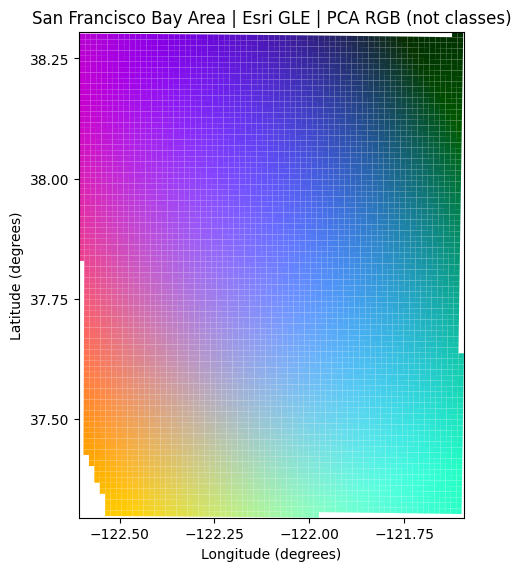

In [4]:
fig = plot_map(bayarea.samples, pca_colors(gle.data), title="San Francisco Bay Area | Esri GLE | PCA RGB (not classes)")
fig.savefig(out / "esri-gle-pca.png", dpi=160)
plt.show()